# 04 · RT-DETR (query-based)

Rubric: *Query-based*. Same protocol and code path as `03_yolo.ipynb` (`ul_dataset.py`): 3-fold
GroupKFold by clip (`splits.json`), train frames every 20th frame, validation frames every 10th frame,
640 px, 12 epochs, OOF COCO metrics with ignored regions as `iscrowd=1` (`common.evaluate`).
Data-specific EDA (grid collisions, GT overlap, density vs queries) is in `03_yolo.ipynb`, section 4.2.

Before a `full` run, attach the output of the `03_yolo` notebook version that trained `yolo_base`
(**Add Input → Your Work → Notebooks**): its per-epoch history is used for the RT-DETR vs YOLO
convergence plot, and its `results.csv` for the comparison of all models.

`MODE`: `quick` (2 clips per fold part, 1 epoch, CPU is enough) · `full` (one experiment on all folds per Kaggle commit).

## 1. Run configuration

In [1]:
MODE = "full"              # "quick" | "full"
EXPERIMENT = "rtdetr_stable"  # key of EXPERIMENTS (section 3)
FOLDS = [0, 1, 2]
REDO_FOLDS = []           # folds to retrain even if an attached output already has them (e.g. [2])

## 2. Setup
Install Ultralytics and get the shared modules (next to this notebook, an attached Kaggle Dataset, or the GitHub repo).

In [2]:
import os, sys, shutil, subprocess, time, urllib.request
from pathlib import Path

os.environ["YOLO_VERBOSE"] = "False"   # no per-layer / per-batch printouts in the notebook
try:
    import ultralytics
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "--timeout", "60", "--retries", "5",
                    "ultralytics==8.4.203", "pycocotools"], check=True, timeout=1800)
    import ultralytics
os.environ["WANDB_MODE"] = "disabled"

REPO_RAW = "https://raw.githubusercontent.com/KaplyshOlha/hw-2/main/notebooks/"

def fetch(url, dst, timeout=60, tries=5):
    # download with a timeout and retries: a stalled GitHub request must not hang a commit for hours
    for i in range(tries):
        try:
            with urllib.request.urlopen(url, timeout=timeout) as r:
                Path(dst).write_bytes(r.read())
            return dst
        except Exception as e:
            if i == tries - 1:
                raise
            print(f"{url}: {type(e).__name__}, retry in 30 s"); time.sleep(30)
SRC_FILES = ["common.py", "ul_dataset.py", "splits.json"]
SRC = next((Path(p) for p in [".", "notebooks"] if all((Path(p) / f).exists() for f in SRC_FILES)), None)
if SRC is None:
    # the GitHub repo is the source of truth (always the latest commit); a copy in an attached
    # dataset is only a fallback for when GitHub is unreachable
    SRC = Path("/tmp/hw2_src"); SRC.mkdir(exist_ok=True)
    for f in SRC_FILES:
        try:
            fetch(REPO_RAW + f, SRC / f, tries=3); print(f"{f}: GitHub")
        except Exception:
            found = [p for pat in ["*", "*/*", "*/*/*"] for p in sorted(Path("/kaggle/input").glob(f"{pat}/{f}"))
                     if "competitions" not in p.parts] if Path("/kaggle/input").exists() else []
            if not found:
                raise
            shutil.copy(found[0], SRC / f); print(f"{f}: {found[0]} (GitHub unreachable)")
sys.path.insert(0, str(SRC))
print("ultralytics", ultralytics.__version__, "| sources:", SRC.resolve())

common.py: GitHub
ul_dataset.py: GitHub
splits.json: GitHub
ultralytics 8.4.203 | sources: /tmp/hw2_src


In [3]:
import importlib
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from IPython.display import display

import common, ul_dataset as uld
importlib.reload(common); importlib.reload(uld)

assert MODE in ("quick", "full")
WORK = Path("/kaggle/working") if Path("/kaggle/working").exists() else Path("outputs")
RUN_ROOT = WORK / ("ul_runs" if MODE != "quick" else "ul_runs_quick")
RESULTS = WORK / ("results.csv" if MODE != "quick" else "results_quick.csv")
DATA_ROOT = Path("/tmp/ul_data")
IMG_DIR = WORK / "images"
for p in (RUN_ROOT, IMG_DIR):
    p.mkdir(parents=True, exist_ok=True)
if MODE != "quick":
    assert torch.cuda.is_available(), "attach a GPU (Settings -> Accelerator)"
DEVICE = "0" if torch.cuda.is_available() else "cpu"
print("device:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "cpu")
uld.restore_from_inputs(RUN_ROOT);   # finished RT-DETR folds and the yolo_base history from attached outputs

device: Tesla T4
restored 13 finished folds from /kaggle/input


## 3. Experiments
Shared protocol as for YOLO (data, 640 px, 12 epochs, Ultralytics default augmentation with mosaic off
for the last 3 epochs, seed 42, `conf=0.001`, `max_det=300`, last-epoch weights). RT-DETR-specific:
`rtdetr-l` COCO weights (the smallest RT-DETR with pretrained weights in Ultralytics), AdamW,
lr0 = 1e-4, weight decay 1e-4, batch 8 (rtdetr-l at batch 16 does not fit a 16 GB T4 with AMP margin).
No NMS: the decoder outputs a set; `max_det` only caps the number of returned queries.

| experiment | change | motivation |
|---|---|---|
| `rtdetr_base` | rtdetr-l, 300 queries | reference (Ultralytics defaults) |
| `rtdetr_stable` | `warmup_bias_lr` 0.1 → 0 | `rtdetr_base` fold 2 collapsed: cls loss → 0 from epoch 2, precision/recall 0 for all 12 epochs while GIoU loss stayed ~2.2 (matched boxes barely overlap → IoU-aware class targets ≈ 0 → trivial all-zero scores). The default bias warmup starts at 10× lr0 in epoch 1 (meant for YOLO + SGD); removing it is the only change |
| `rtdetr_nq500` | `rtdetr_stable` + 500 decoder queries | queries vs scene density (EDA 4.2c): more queries than the densest frames, to check whether recall in crowded scenes is query-limited |
| `rtdetr_bblr` | `rtdetr_stable` + backbone lr = 0.1 · lr0 (encoder/decoder keep lr0) | separate learning rates: keep COCO backbone features stable while the transformer adapts to 8 classes and tiny objects |

In [4]:
BASE = uld.Config(experiment="rtdetr_base", model="rtdetr", weights="rtdetr-l.pt", device=DEVICE,
                  optimizer="AdamW", lr0=1e-4, weight_decay=1e-4, momentum=0.9, batch=8,
                  notes="rtdetr-l, 300 queries, AdamW 1e-4")
STABLE = uld.make_config(BASE, experiment="rtdetr_stable", warmup_bias_lr=0.0,
                         notes="rtdetr-l, no bias-lr warmup spike")
EXPERIMENTS = {
    "rtdetr_base": BASE,
    "rtdetr_stable": STABLE,
    "rtdetr_nq500": uld.make_config(STABLE, experiment="rtdetr_nq500", num_queries=500, notes="500 queries"),
    "rtdetr_bblr": uld.make_config(STABLE, experiment="rtdetr_bblr", backbone_lr_mult=0.1,
                                   notes="backbone lr x0.1"),
}
cfg = EXPERIMENTS[EXPERIMENT]
if MODE == "quick":
    cfg = uld.make_config(cfg, epochs=1, close_mosaic=0, batch=2, workers=2, fps_iters=3, fps_warmup=1, imgsz=320)
print(cfg)

Config(experiment='rtdetr_stable', model='rtdetr', owner='B', weights='rtdetr-l.pt', arch='', imgsz=640, train_stride=20, eval_stride=10, epochs=12, batch=8, optimizer='AdamW', lr0=0.0001, lrf=0.01, momentum=0.9, weight_decay=0.0001, warmup_epochs=1.0, warmup_bias_lr=0.0, close_mosaic=3, amp=True, cache=False, box=7.5, cls=0.5, dfl=1.5, nwd=0.0, nwd_c=12.8, num_queries=300, backbone_lr_mult=1.0, mosaic=1.0, scale=0.5, fliplr=0.5, conf=0.001, iou=0.7, max_det=300, workers=4, device='0', pred_batch=16, fps_warmup=10, fps_iters=50, notes='rtdetr-l, no bias-lr warmup spike')


## 4. Data and folds
Same frames and folds as every other model; the converted frames are cached in `/tmp/ul_data`.

In [5]:
common.seed_everything()
images, anns = common.load_gt(cache="/tmp/gt_cache.pkl")
splits = common.load_splits(SRC / "splits.json")
if MODE == "quick":
    for f in splits["folds"]:
        f["train_clips"], f["val_clips"] = f["train_clips"][:2], f["val_clips"][:2]
conv = uld.Converter(images, anns, DATA_ROOT)

## 5. Train and predict
Every fold in `FOLDS` (finished folds are skipped, an interrupted fold resumes from `last.pt`);
OOF metrics are logged to `results.csv` once all 3 folds are finished.

In [6]:
t0 = time.time()
metrics = uld.run_experiment(cfg, images, anns, splits, FOLDS, RUN_ROOT, RESULTS, conv, redo=REDO_FOLDS)
print(f"{(time.time() - t0) / 60:.1f} min")

[rtdetr_stable] fold 0: 922 train / 912 val frames
rtdetr-l.pt: copied from /kaggle/input/notebooks/darinopri/notebook3ab9301e43/rtdetr-l.pt


/usr/local/lib/python3.13/dist-packages/torch/autograd/graph.py:869: UserWarning: grid_sampler_2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:160.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass
/usr/local/lib/python3.13/dist-packages/ray/train/_internal/session.py:683: UserWarning: `get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torch/autograd/graph.py:869: UserWarning: grid_sampler_2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can 

[rtdetr_stable] fold 0: 16.9 min, 15.9 FPS
[rtdetr_stable] fold 1: 923 train / 913 val frames


/usr/local/lib/python3.13/dist-packages/torch/autograd/graph.py:869: UserWarning: grid_sampler_2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:160.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass
/usr/local/lib/python3.13/dist-packages/torch/autograd/graph.py:869: UserWarning: grid_sampler_2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:160.)
  return Variable._execution

[rtdetr_stable] fold 1: 16.5 min, 19.2 FPS
[rtdetr_stable] fold 2: done, skipped
42.6 min


In [7]:
MAIN = ["mAP", "AP50", "AP75", "AP_small", "AP_medium", "AP_large", "AR500"]
PER_CLASS = [f"AP_{c}" for c in common.CLASSES]
if metrics is not None:
    display(metrics[MAIN].round(4))
    display(metrics.loc[["oof"], PER_CLASS].round(4))

,mAP,AP50,AP75,AP_small,AP_medium,AP_large,AR500
0,0.1987,0.3708,0.1804,0.0942,0.1677,0.3695,0.3949
1,0.1746,0.3376,0.1552,0.0566,0.1517,0.3433,0.3447
2,0.1928,0.3787,0.1758,0.0680,0.1654,0.3557,0.3942
mean,0.1887,0.3624,0.1705,0.0730,0.1616,0.3562,0.3779
std,0.0102,0.0178,0.0109,0.0158,0.0071,0.0107,0.0235
oof,0.1825,0.3528,0.1650,0.0611,0.1541,0.3482,0.3747


,AP_person,AP_bicycle,AP_car,AP_van,AP_truck,AP_tricycle,AP_bus,AP_motor
oof,0.1936,0.0543,0.4316,0.1382,0.096,0.1286,0.3224,0.1006


## 6. Convergence: RT-DETR vs YOLO under the same budget
Validation mAP@[.5:.95] after every epoch on fold 0 (Ultralytics validator: same frames, same metric
for both models, but without ignored regions, so absolute values are below the OOF metric).
Same data, 12 epochs, 640 px. If the RT-DETR curve is still rising at epoch 12, it has not converged
within the budget.

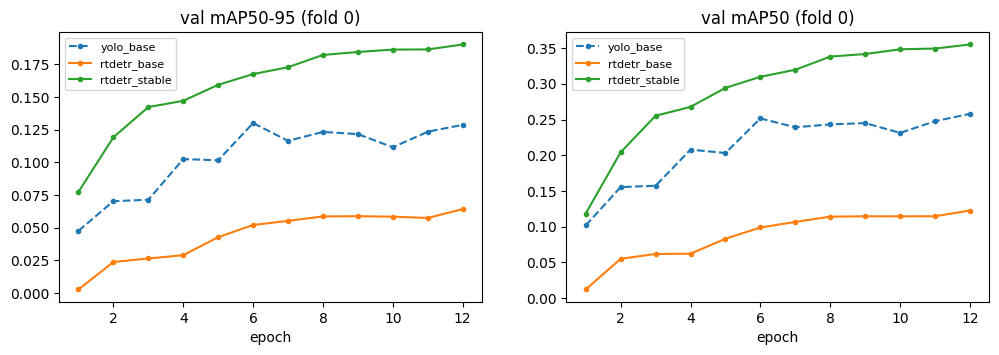

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
curves = {}
for e in ["yolo_base", *EXPERIMENTS]:
    done = uld.load_done(RUN_ROOT, e)
    if 0 in done and done[0]["history"]:
        curves[e] = pd.DataFrame(done[0]["history"])
for e, h in curves.items():
    style = "--" if e.startswith("yolo") else "-"
    ax[0].plot(h["epoch"], h["metrics/mAP50-95(B)"], style, marker="o", ms=3, label=e)
    ax[1].plot(h["epoch"], h["metrics/mAP50(B)"], style, marker="o", ms=3, label=e)
ax[0].set_title("val mAP50-95 (fold 0)"); ax[1].set_title("val mAP50 (fold 0)")
for a in ax:
    a.set_xlabel("epoch"); a.legend(fontsize=8)
fig.savefig(IMG_DIR / "04_rtdetr_vs_yolo_curves.png"); plt.show()
if "yolo_base" not in curves:
    print("yolo_base history not found: attach the 03_yolo notebook output (Add Input)")

**Observations (convergence):** TBD

## 7. Comparison of all models
Latest logged run of every experiment from this session, the attached `03_yolo` output and the
repo `results.csv` (teammate's torchvision models): OOF metrics on the same folds and frames.

In [9]:
paths = [RESULTS, *uld._input_files("/kaggle/input", "results*.csv")]
try:
    fetch(REPO_RAW + "results.csv", "/tmp/repo_results.csv", tries=2); paths.append(Path("/tmp/repo_results.csv"))
except Exception as e:
    print("repo results.csv not available:", e)
frames = [pd.read_csv(p) for p in paths if Path(p).exists() and Path(p).stat().st_size
          and (MODE == "quick" or "quick" not in Path(p).name)]
allres = pd.concat(frames, ignore_index=True).astype({"fold": str}).drop_duplicates(["run_id", "fold"]) if frames else pd.DataFrame()
if len(allres):
    last = allres.sort_values("timestamp").groupby("experiment").run_id.last()
    r = allres[allres.run_id.isin(last) & (allres.fold == "oof")].set_index("experiment")
    std = allres[allres.run_id.isin(last) & (allres.fold == "std")].set_index("experiment")["mAP"]
    summ = r[["model", *MAIN, "fps", "train_min"]].assign(mAP_std=std).sort_values("mAP", ascending=False)
    display(summ.round(4))

,model,mAP,AP50,AP75,AP_small,AP_medium,AP_large,AR500,fps,train_min,mAP_std
experiment,,,,,,,,,,,
yolo_1024,yolo,0.1892,0.3646,0.1735,0.0617,0.1644,0.3498,0.3160,48.51,28.0,0.0141
rtdetr_stable,rtdetr,0.1825,0.3528,0.1650,0.0611,0.1541,0.3482,0.3747,18.03,52.0,0.0102
yolo_p2,yolo,0.0868,0.1955,0.0698,0.0284,0.0890,0.1706,0.1849,48.96,24.0,0.0056
rtdetr_base,rtdetr,0.0327,0.0668,0.0311,0.0119,0.0248,0.0611,0.1349,18.29,51.7,0.0278


**Observations (comparison):** TBD

## 8. Outputs
Merge this session's `results.csv` with the repo copy into `results_merged.csv` (commit it as `notebooks/results.csv`).

In [10]:
if MODE == "full" and RESULTS.exists():
    merged = WORK / "results_merged.csv"
    try:
        fetch(REPO_RAW + "results.csv", merged, tries=2)
    except Exception as e:
        print("repo results.csv not available:", e); merged.unlink(missing_ok=True)
    common.merge_results(str(RESULTS), str(merged))
    print(f"{merged}: {len(pd.read_csv(merged))} rows")
for p in sorted(RUN_ROOT.glob("*/fold*/done.json")):
    print(p.parent)

/kaggle/working/results_merged.csv: 18 rows
/kaggle/working/ul_runs/rtdetr_base/fold0
/kaggle/working/ul_runs/rtdetr_base/fold1
/kaggle/working/ul_runs/rtdetr_base/fold2
/kaggle/working/ul_runs/rtdetr_stable/fold0
/kaggle/working/ul_runs/rtdetr_stable/fold1
/kaggle/working/ul_runs/rtdetr_stable/fold2
/kaggle/working/ul_runs/yolo_1024/fold0
/kaggle/working/ul_runs/yolo_1024/fold1
/kaggle/working/ul_runs/yolo_1024/fold2
/kaggle/working/ul_runs/yolo_base/fold0
/kaggle/working/ul_runs/yolo_base/fold1
/kaggle/working/ul_runs/yolo_base/fold2
/kaggle/working/ul_runs/yolo_p2/fold0
/kaggle/working/ul_runs/yolo_p2/fold1
/kaggle/working/ul_runs/yolo_p2/fold2


## 9. Conclusions
TBD